# Autoencoder without position channels

RGB → CNN → 16 × 16 notes → reconstructed RGB. Same model and pixel/edge loss as the original notebook, except it receives **3 RGB channels instead of RGB + x/y**. Convolutions and padding still provide spatial biases.

Run top to bottom. Only rerun training when you want a new model; changing playback settings does not require retraining. Images are stretched to 64 × 64, matching the original experiment. Displayed images are training examples, not a held-out test.


**Playback update:** argmax selects one pitch per column; matching consecutive pitches sustain. No chords, sampling, or melody smoothing. The model and training are unchanged.


In [ ]:
%pip install torch numpy pillow matplotlib ipython

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Works from the repository root or musician/.
HERE = next(p / "musician" for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "musician/experiment_utils.py").is_file())
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from experiment_utils import DEFAULT_DATA, image_paths, load_image, export_sound

DATA = DEFAULT_DATA  # Or DEFAULT_DATA / "oil-paint".
paths = image_paths(DATA)
print(f"Found {len(paths)} images in {DATA}")


Found 117 images in /Users/sarinali/Projects/3d-painting/data/monet/by-medium


## Train

Defaults match the original notebook: 100 epochs, seed 0, CPU, batch size 8. Start with 10 epochs for a quick check. The model stays in kernel memory.

Training on 117 paintings, CPU, seed 0.
Epoch 1/100: 0.2072
Epoch 10/100: 0.1205
Epoch 20/100: 0.1095
Epoch 30/100: 0.1061
Epoch 40/100: 0.1045
Epoch 50/100: 0.1039
Epoch 60/100: 0.1029
Epoch 70/100: 0.1031
Epoch 80/100: 0.1022
Epoch 90/100: 0.1020
Epoch 100/100: 0.1018


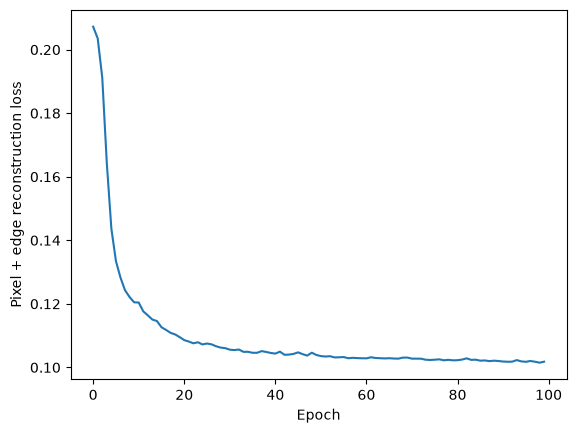

In [2]:
import torch
from torch import nn
from torch.nn import functional as F

EPOCHS = 100  # Try 10 for a quick first run.
SEED = 0
EXPERIMENT = "no-position"

torch.manual_seed(SEED)
x = torch.from_numpy(np.stack([load_image(p) for p in paths])).permute(0, 3, 1, 2)
# Identical to the notebook except the encoder takes 3 channels, not 5.
encoder = nn.Sequential(
    nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(16, 16, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid(),
)
decoder = nn.Sequential(
    nn.Upsample(scale_factor=2, mode='nearest'),
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
    nn.Upsample(scale_factor=2, mode='nearest'),
    nn.Conv2d(16, 3, 3, padding=1), nn.Sigmoid(),
)
optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=1e-3)
losses = []
print(f'Training on {len(paths)} paintings, CPU, seed {SEED}.', flush=True)
for epoch in range(EPOCHS):
    total = 0.0
    for indices in torch.randperm(len(x)).split(8):
        batch = x[indices]
        reconstructed = decoder(encoder(batch))
        edges = sum(F.l1_loss(torch.diff(reconstructed, dim=d), torch.diff(batch, dim=d))
                    for d in (2, 3))
        loss = F.l1_loss(reconstructed, batch) + 0.5 * edges
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(batch)
    losses.append(total / len(x))
    if (epoch + 1) % 10 == 0 or epoch == 0 or epoch + 1 == EPOCHS:
        print(f'Epoch {epoch + 1}/{EPOCHS}: {losses[-1]:.4f}', flush=True)


plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Pixel + edge reconstruction loss")
plt.show()
encoder.eval()
decoder.eval()

def get_result(index):
    with torch.no_grad():
        notes = encoder(x[index:index + 1])
        reconstruction = decoder(notes)[0].permute(1, 2, 0).numpy()
    return notes[0, 0].numpy(), reconstruction


## Browse and listen

Change `START`, `COUNT`, or `SCALE` and rerun the next two cells without retraining. WAV files are saved in `output/no-position/`. Repeated winning pitches are merged into sustained notes.

In [7]:
# Rerun this cell and the display cell to browse or change sound. No training needed.
START = 0
COUNT = 6
SCALE = "major_pentatonic"  # major, minor, minor_pentatonic, chromatic
ROOT_MIDI = 48  # C3
THRESHOLD = 0.0  # Increase to silence faint notes.


In [ ]:
from pathlib import Path
import sys, importlib
HERE = next(p / "musician" for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "musician/experiment_utils.py").is_file())
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
import experiment_utils
importlib.reload(experiment_utils)  # Pick up playback updates in an existing kernel.
from experiment_utils import sonify, melody_events, synthesize_events, export_sound

assert START >= 0 and COUNT > 0
indices = list(range(START, min(START + COUNT, len(paths))))
assert indices, "START is past the last image."
OUTPUT = HERE / "output" / EXPERIMENT
OUTPUT.mkdir(parents=True, exist_ok=True)
for index in indices:
    grid, reconstruction = get_result(index)
    columns = 3 if reconstruction is not None else 2
    fig, axes = plt.subplots(1, columns, figsize=(4 * columns, 3.5))
    axes[0].imshow(load_image(paths[index]))
    axes[0].set_title(f"#{index} · {paths[index].parent.name}")
    axes[0].axis("off")
    if reconstruction is not None:
        axes[1].imshow(reconstruction)
        axes[1].set_title("Reconstruction")
        axes[1].axis("off")
    axes[-1].imshow(grid, origin="lower", aspect="auto", vmin=0, vmax=1)
    events = melody_events(grid, SCALE, ROOT_MIDI, THRESHOLD)
    for event in events:
        if event['row'] is not None:
            axes[-1].hlines(event['row'], event['start'] - 0.5,
                            event['start'] + event['steps'] - 0.5, color="white", linewidth=2)
    axes[-1].set(title=f"Melody · {SCALE}", xlabel="Time step", ylabel="Pitch row")
    plt.tight_layout()
    plt.show()
    # Include controls in filenames to keep different listening experiments separate.
    name = f"melody-{index:03d}-{SCALE}-root{ROOT_MIDI}-threshold{THRESHOLD:g}.wav"
    wav = OUTPUT / name
    export_sound(grid, wav, SCALE, ROOT_MIDI, THRESHOLD)
    print(paths[index].name)
    display(Audio(filename=str(wav)))


## Do visually similar paintings produce similar melodies?

Run after training and playback; no retraining. Compare an explicit low-resolution RGB appearance measure with both raw-grid distances and musical interval-contour distances. Positive rank correlation means closer-looking images tend to have closer outputs under these particular measures. The permutation check randomizes painting–melody assignments. These are exploratory training-set results, not proof of semantic similarity, generalization, or universal music–art associations. Compare held-out images, direct-image baselines, and multiple training seeds before drawing conclusions. A constant transposed melody has the same interval contour; it does not necessarily sound identical.

Change `INDEX` before running to inspect its three closest visual neighbors.


In [ ]:
encoder.eval()
ENCODE = encoder
# Run after training. This does not update model weights.
ANALYSIS_COUNT = len(paths)  # All loaded paintings, in the current path order.
PERMUTATIONS = 500
analysis_scale = globals().get("SCALE", "major_pentatonic")
analysis_root = globals().get("ROOT_MIDI", 48)
from experiment_utils import midi_notes
n = min(ANALYSIS_COUNT, len(paths))
assert n >= 4, "Use at least four paintings."
with torch.no_grad():
    all_grids = torch.cat([ENCODE(x[start:min(start + 8, n)])
                           for start in range(0, n, 8)])[:, 0].numpy()
# An independent, explicit visual measure: spatial 16 × 16 RGB appearance.
visual_features = F.adaptive_avg_pool2d(x[:n], (16, 16)).flatten(1).numpy()
pitches = np.array(midi_notes(all_grids.shape[1], analysis_scale, analysis_root))
melody_rows = all_grids.argmax(axis=1)
melody_pitches = pitches[melody_rows]
intervals = np.diff(melody_pitches, axis=1)

def pair_dist(features):
    flat = features.reshape(len(features), -1)
    return np.abs(flat[:, None] - flat[None, :]).mean(axis=2)

def ranks(values):
    _, inverse, counts = np.unique(values, return_inverse=True, return_counts=True)
    middle_ranks = np.cumsum(counts) - (counts + 1) / 2
    return middle_ranks[inverse]

visual_distance = pair_dist(visual_features)
grid_distance = pair_dist(all_grids)
melody_distance = pair_dist(intervals)  # Interval contour; ignores overall transposition.
triangle = np.triu_indices(n, 1)
visual_ranks = ranks(visual_distance[triangle])

def correlation(distance):
    other = ranks(distance[triangle])
    if np.std(visual_ranks) == 0 or np.std(other) == 0:
        return float("nan")
    return float(np.corrcoef(visual_ranks, other)[0, 1])

print(f"{n} paintings; low-resolution RGB appearance versus:")
print(f"  learned grid distance: rank correlation = {correlation(grid_distance):.3f}")
observed = correlation(melody_distance)
print(f"  melody interval distance: rank correlation = {observed:.3f}")
# Shuffle painting↔melody assignments, not individual pair entries.
rng = np.random.default_rng(0)
null = []
for _ in range(PERMUTATIONS):
    order = rng.permutation(n)
    null.append(correlation(melody_distance[np.ix_(order, order)]))
if np.isfinite(observed):
    p = (1 + np.sum(np.abs(null) >= abs(observed))) / (PERMUTATIONS + 1)
    print(f"  exploratory two-sided label-permutation p = {p:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for axis, matrix, title in zip(axes, [visual_distance, grid_distance, melody_distance],
                              ["Visual distance", "Grid distance", "Melody interval distance"]):
    image = axis.imshow(matrix)
    axis.set_title(title)
    axis.set_xlabel("Painting index")
    fig.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

# Inspect the nearest visual neighbors, with melody contours underneath.
i = globals().get("INDEX", 0)
assert 0 <= i < n
neighbors = np.argsort(visual_distance[i])
chosen = [i] + [int(j) for j in neighbors if j != i][:3]
fig, axes = plt.subplots(2, len(chosen), figsize=(4 * len(chosen), 5), squeeze=False)
for col, index in enumerate(chosen):
    axes[0, col].imshow(x[index].permute(1, 2, 0).numpy())
    axes[0, col].set_title(f"#{index}" + (" · query" if index == i else " · visual neighbor"))
    axes[0, col].axis("off")
    axes[1, col].step(range(16), melody_pitches[index], where="mid")
    axes[1, col].set_ylim(pitches.min() - 1, pitches.max() + 1)
    axes[1, col].set_xlabel("Time step")
    axes[1, col].set_ylabel("MIDI pitch")
    print(f"#{index}: {paths[index].name}")
plt.tight_layout()
plt.show()


## Trace a note back to pixels

The encoder receptive field is 15 × 15 pixels, with a stride of 4. Output cell `(r, t)` sees input rows `4r−7…4r+7` and columns `4t−7…4t+7`, clipped at boundaries. Argmax compares all pitch rows, so a time step's winner can depend on the whole vertical strip. Position channels add coordinates but do not enlarge the receptive field.

Argmax itself has no useful ordinary gradient. This cell instead differentiates the current winner-minus-runner-up activation margin. It measures local sensitivity, not a causal explanation or a guarantee about larger edits. Model weights are unchanged.


In [ ]:
encoder.eval()
ENCODE = encoder
# Which pixels affect the winning pitch's margin over its runner-up?
PAINTING_INDEX = 1
TIME_STEP = 8
assert 0 <= PAINTING_INDEX < len(x) and 0 <= TIME_STEP < 16
sample = x[PAINTING_INDEX:PAINTING_INDEX + 1].detach().clone().requires_grad_(True)
activation = ENCODE(sample)[0, :, :, TIME_STEP].squeeze(0)
winning_rows = activation.detach().topk(2).indices
margin = activation[winning_rows[0]] - activation[winning_rows[1]]
gradient, = torch.autograd.grad(margin, sample)
importance = gradient[0].abs().sum(dim=0).numpy()
print(f"Winner row {int(winning_rows[0])}; runner-up row {int(winning_rows[1])}; margin {margin.item():.4f}")
print("Small margins mean the discrete melody can change after a small activation change.")
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample.detach()[0].permute(1, 2, 0).numpy())
# Column t can depend only on x coordinates 4t−7 ... 4t+7, clipped to image.
left, right = max(0, 4 * TIME_STEP - 7), min(63, 4 * TIME_STEP + 7)
axes[0].axvspan(left - .5, right + .5, alpha=.25, color="orange")
axes[0].set_title("Possible influence: this time step")
axes[1].imshow(importance, cmap="magma")
axes[1].set_title("Actual local sensitivity · winner minus runner-up")
plt.tight_layout()
plt.show()
